# 第 4 课｜岗位聚类与项目交付

**90 分钟：原理与向量化 20′ → KMeans 30′ → 解释与聚焦分析 25′ → 项目汇报 15′**

目标：在数据相关候选岗位中，探索文本相似的岗位群，用关键词和代表职位解释聚类。
聚类是无监督探索，不是招聘预测，也没有“分类准确率”。若分群主要反映语言或公司模板，
这也是需要报告的发现，而不是强行命名成职业方向。

> **增强版阅读方法**：先看本节问题，预测输出，再运行代码，最后解释数字。
> 关键代码已加中文注释，说明“为什么做、参数是什么、结果的行列单位是什么”。
> 标有【主线】的段落用于课堂；【拓展】用于教师演示或课后，不要求90分钟内完成所有扩展。
> 长代码按完整步骤拆成较短单元；每本仍需从上到下依次运行。

In [1]:
# Path把文件路径当作对象处理；用 / 拼接路径可兼容不同操作系统。
from pathlib import Path
import sys, json, re
# NumPy处理数组和数值；np只是约定俗成的简称，不是Python关键字。
import numpy as np
# Pandas处理带行列标签的表格；Series是一列，DataFrame是一张表。
import pandas as pd
# display显示表格，Markdown把动态生成的结论渲染成Notebook文字。
from IPython.display import display, Markdown

# 支持从项目根目录、课程目录或 notebooks 目录启动。
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / 'course_utils.py').exists()), None)
if ROOT is None:
    ROOT = next((p / 'data_analysis202612' for p in candidates
                 if (p / 'data_analysis202612' / 'course_utils.py').exists()), None)
assert ROOT is not None, '请从项目根目录或课程目录启动 Jupyter'
# 将课程目录加入模块搜索路径，才能导入同目录的course_utils.py。
sys.path.insert(0, str(ROOT))
# 教学工具只封装路径、清洗和绘图；SKILLS是词典，KEY是复合身份字段，SEED固定随机种子。
from course_utils import *
# 以下设置只影响屏幕展示，不删数据、不改变统计结果；完整结果仍会导出。
pd.set_option('display.max_columns', 14)
pd.set_option('display.max_colwidth', 65)
pd.set_option('display.max_rows', 20)
print('课程目录：', ROOT)
print('Python：', sys.version.split()[0])
print('解释器：', sys.executable)

课程目录： /Users/luosen/WorkBuddy/JobsCrawler/data_analysis202612
Python： 3.10.16
解释器： /Users/luosen/WorkBuddy/JobsCrawler/data_analysis202612/.venv/bin/python


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import TruncatedSVD
from threadpoolctl import threadpool_limits
setup_plotting()
jobs = pd.read_parquet(DATA / 'processed' / 'jobs_features.parquet')
# 先固定聚类范围：标题命中且正文至少40字符；太短文本难以产生可靠词项。
candidate = jobs.loc[jobs.focus_candidate & jobs.text_length.ge(40)].copy()
candidate['han_share'] = candidate['analysis_text'].map(
    lambda s: len(re.findall(r'[一-鿿]', s)) / max(1, len(re.findall(r'[a-zA-Z一-鿿]', s))))
# 此课聚焦中文为主的岗位；阈值是教学规则，不是经过训练的语言识别器。
# 明确把研究范围限定为中文为主；排除的英文记录保留在全量特征表中，不删除原始数据。
focus = candidate.loc[candidate.han_share.ge(0.3)].copy()
intro_pattern = r'(?:团队|部门|公司)介绍[：:].*?(?=\s*1[、.．）)])'
intern_pattern = r'(?:日常实习|项目实习|转正实习)[：:][^。]*。'
focus['description_core'] = (focus['description_clean'].str.replace(intro_pattern, ' ', regex=True)
                             .str.replace(intern_pattern, ' ', regex=True))
focus['text_normalized'] = (focus['description_core'] + ' ' + focus['requirement_clean']).str.lower().str.replace(
    r'\s+', ' ', regex=True).str.strip()
# 只在有明确介绍标记和编号职责时移除介绍；无编号文本保留，避免贪婪删除。
assert re.sub(intro_pattern, ' ', '团队介绍：公司简介。 1、分析数据').strip() == '1、分析数据'
assert re.sub(intro_pattern, ' ', '团队介绍：无编号职责需保留') == '团队介绍：无编号职责需保留'
# 相同处理后文本只训练一次，避免重复模板被反复加权；之后还会映射回所有候选职位。
training = focus.drop_duplicates('text_normalized').copy()
print('初始候选：', len(candidate), '；语言范围外：', len(candidate)-len(focus))
print('中文为主候选：', len(focus), '；唯一文本：', len(training), '；重复文本：', len(focus)-len(training))
assert len(training) >= 50
display(training[['company_name', 'title_clean']].sample(10, random_state=SEED))

初始候选： 1138 ；语言范围外： 16
中文为主候选： 1122 ；唯一文本： 1028 ；重复文本： 94


,company_name,title_clean
17097,腾讯,商业分析师/商业分析经理（金融科技方向）
23702,阿里巴巴,阿里国际风险管理-风控数据分析-日常实习生
15118,字节跳动,商业化数据科学实习生-商业变现
4246,字节跳动,数据分析师（拉丁美洲）-国际电商
16560,字节跳动,算法实习生（数据湖基础设施与数据分析方向） - 火山方舟
16540,字节跳动,AI数据分析运营（生态方向）实习生 - TikTok
6483,字节跳动,数据分析专家（MaaS） - 火山方舟
10182,字节跳动,大促数据科学实习生 - 抖音电商
29465,美团,【LongCat大模型人才校招】基础模型 - 预训练数据策略和数据科学研究
25247,京东,数据科学岗


## 0A. 【主线】先用二维例子理解“分配—更新”，再进入文本矩阵

KMeans反复执行：选中心 → 把每点分到最近中心 → 用群内均值更新中心。
它优化群内平方距离，不理解职位含义。特征的尺度、相似度定义和样本范围都会影响结果。
下面6条记录是人工构造的二维教学示例，不是模型对真实岗位的结论。

In [3]:
toy_points = np.array([[0, 1], [1, 0], [1, 1], [7, 8], [8, 7], [8, 8]], dtype=float)
initial_centers = np.array([[0, 0], [8, 8]], dtype=float)
# 广播得到6×2×2差值：6个点、2个中心、2个坐标；沿坐标轴求平方和。
squared_distances = ((toy_points[:, None, :] - initial_centers[None, :, :]) ** 2).sum(axis=2)
# 每一行代表一个点到各中心的距离；argmin返回最近中心的列号，也就是群标签。
toy_labels = squared_distances.argmin(axis=1)
updated_centers = np.vstack([toy_points[toy_labels == group].mean(axis=0) for group in range(2)])
display(pd.DataFrame({'x': toy_points[:, 0], 'y': toy_points[:, 1], '分配群': toy_labels}))
print('更新前中心：', initial_centers.tolist())
print('更新后中心：', updated_centers.round(3).tolist())
assert np.bincount(toy_labels).tolist() == [3, 3]
assert np.allclose(updated_centers[0], [2/3, 2/3])

,x,y,分配群
0,0.0,1.0,0
1,1.0,0.0,0
2,1.0,1.0,0
3,7.0,8.0,1
4,8.0,7.0,1
5,8.0,8.0,1


更新前中心： [[0.0, 0.0], [8.0, 8.0]]
更新后中心： [[0.667, 0.667], [7.667, 7.667]]


## 1. 先看一个失败基线，再改进表征

第一次试验使用原文字符2—4元片段，聚类中心充满编号、标点、公司介绍。
指标看起来更高，也未必对应职业方向。下面保留一个K=4的反例供课堂观察。

正式模型改用jieba分词，移除标点编号、常见套话和公司名称；只对中文字符占字母/汉字至少30%的候选训练。
英文为主职位留在全量分析表，另列排除数量，不能把中文子集结论推广到英文岗位。
公司/团队介绍仅在明确标记与编号职责之间删除，原文不覆盖，便于回查。
模型输入仍只有职责与要求，没有直接输入标题、公司和城市；残留模板依然可能影响分群。

In [4]:
baseline_vectorizer = TfidfVectorizer(analyzer='char', ngram_range=(2, 4), min_df=5, max_df=.8, max_features=6000)
baseline_X = baseline_vectorizer.fit_transform(training['analysis_text'])
# 限制数值库并行线程，减少课堂机器负载并让同一环境的重复运行更稳定。
with threadpool_limits(limits=1):
    baseline = KMeans(n_clusters=4, n_init=5, random_state=SEED).fit(baseline_X)
baseline_terms = baseline_vectorizer.get_feature_names_out()
baseline_terms_table = pd.DataFrame([
    {'cluster': i, 'top_fragments': repr(baseline_terms[np.argsort(center)[::-1][:8]].tolist())}
    for i, center in enumerate(baseline.cluster_centers_)])
display(baseline_terms_table)
csv_export(baseline_terms_table, '04_failed_char_baseline')

import jieba
stopwords = set('我们 你们 他们 以及 相关 工作 岗位 职责 要求 负责 具有 能够 良好 优秀 熟悉 优先 能力 以上 进行 包括 公司 团队 业务 经验 具备 使用 参与 通过 方向 支持 完成 基于 对于 了解 掌握 任职 本科 硕士 学历 职位 我们的 字节 跳动 字节跳动 抖音 今日头条 腾讯 美团 阿里巴巴 快手 小红书 京东 拼多多 滴滴 携程 tiktok bytedance about us and the of to in for with on is are be as or that you your our we will have at an a it can from this their global products team skills experience role work ability strong preferred responsibilities qualifications opportunity equal employment diversity inclusive inclusion candidate candidates disability reasonable accommodation accommodations provide needs request requests apply qualified applicants all people world join also more other which who was were has not one across development new including related good etc such years year degree bachelor master phd'.split())
for word in ['数据分析', '商业分析', '数据科学', '数据挖掘', '机器学习', '深度学习', '用户增长', '实验设计', '数据仓库',
             '指标体系', '因果推断', '数理统计', '数据建模', '可视化', '推荐算法', '经营分析', '数据治理', '数据产品', '统计分析', '增长策略']:
    jieba.add_word(word)

# 分词函数决定模型“看见什么”；过滤规则会影响词表与结果，应与参数一起归档。
def tokenize(text):
    return [w for w in jieba.lcut(text.lower()) if w not in stopwords
            and re.fullmatch(r'[a-z][a-z0-9_+#.-]+|[一-鿿]{2,}', w)]

vectorizer = TfidfVectorizer(tokenizer=tokenize, token_pattern=None, min_df=5, max_df=.8,
                             max_features=4000, sublinear_tf=True)
# 只在唯一文本上学习词表与IDF；X为稀疏矩阵，不需要转成几千列的稠密大表。
X = vectorizer.fit_transform(training['text_normalized'])
assert (X.getnnz(axis=1) > 0).all(), '存在零向量，请检查文本/分词参数'
assert np.isfinite(X.data).all(), '向量包含非有限值'
csv_export(pd.DataFrame({'term': vectorizer.get_feature_names_out()}), '04_model_vocabulary')
print('训练矩阵：', X.shape, '；非零元素：', X.nnz)

,cluster,top_fragments
0,0,"['抖音', '团队', '实习', '提供', '用户', '； 2、', '20', '科学']"
1,1,"['. ', '1. ', '2. ', ' 2. ', '3. ', ' 3. ', ' 2.', '1.']"
2,2,"['ktok', 'tik', 'ikto', 'kto', 'kt', 'tikt', 'ikt', 'ik']"
3,3,"['产品', ' 2、', '2、', '1、', '据分', '数据分', '据分析', '数据分析']"


Building prefix dict from the default dictionary ...


Loading model from cache /var/folders/3q/wv1kfqy544v7lnd3d_75mg3w0000gn/T/jieba.cache


Loading model cost 0.486 seconds.


Prefix dict has been built successfully.


训练矩阵： (1028, 1678) ；非零元素： 85581


## 2. 比较 K=3、4、5、6，并检查稳定性

KMeans 将文本分成K群，最小化群内距离。固定种子让课堂结果可复现。
轮廓系数用于比较本次候选方案；分值低说明分群边界较弱，没有普适“合格线”。
同时检查最小群大小和两个随机种子下的 ARI（一致性指标，不是准确率）。
选择：优先保留最小群≥20且ARI≥0.6的方案，再取轮廓系数较高者；若无方案则回退并提示。
0.6是本课堂预设的稳定性筛选规则，不是行业通用标准。规则公开且可修改。
这只是起点，最终解释仍依赖代表文本审核。

In [5]:
# 模型对象与评估指标分开存：models用于取回选中的模型，rows用于比较参数方案。
models, rows = {}, []
# 限制数值库并行线程，减少课堂机器负载并让同一环境的重复运行更稳定。
with threadpool_limits(limits=1):
    # 只比较少量K便于课堂解释；K不是自然界已知的职业数量，而是探索参数。
    for k in [3, 4, 5, 6]:
        # n_init=10尝试10次初始化，max_iter限制每次迭代；random_state使随机起点可复现。
        model = KMeans(n_clusters=k, random_state=SEED, n_init=10, max_iter=200)
        # fit寻找群中心，predict把每行分配到最近中心；标签编号本身没有顺序或业务含义。
        labels = model.fit_predict(X)
        assert np.isfinite(model.cluster_centers_).all() and np.isfinite(model.inertia_)
        other = KMeans(n_clusters=k, random_state=SEED+1, n_init=10, max_iter=200).fit_predict(X)
        score = silhouette_score(X, labels, metric='cosine', sample_size=min(600, X.shape[0]), random_state=SEED)
        models[k] = model
        rows.append({'k': k, 'silhouette_cosine': score, 'inertia': model.inertia_,
                     'smallest_cluster': int(np.bincount(labels).min()),
                     'seed_ARI': adjusted_rand_score(labels, other)})
comparison = pd.DataFrame(rows)
eligible = comparison.loc[comparison.smallest_cluster.ge(20) & comparison.seed_ARI.ge(0.6)]
if eligible.empty:
    eligible = comparison.loc[comparison.smallest_cluster.ge(20)]
    print('警示：没有方案满足稳定性门槛，仅作探索，需人工检查。')
if eligible.empty:
    eligible = comparison
    print('警示：所有方案都有小群，需人工检查。')
best_k = int(eligible.sort_values(['silhouette_cosine', 'k'], ascending=[False, True]).iloc[0]['k'])
model = models[best_k]
# labels_与训练输入行序一致；不要在训练后随意重排training再按位置贴标签。
training['cluster'] = model.labels_
# 对完整候选只用transform，沿用训练词表与IDF；不能重新fit成另一套坐标。
focus_X = vectorizer.transform(focus['text_normalized'])

,k,silhouette_cosine,inertia,smallest_cluster,seed_ARI
0,3,0.0346,881.9133,31,0.8969
1,4,0.0361,873.9095,30,0.4533
2,5,0.0349,867.6250,30,0.5962
3,6,0.0301,860.3261,27,0.4694


按预先声明规则选择 K = 3


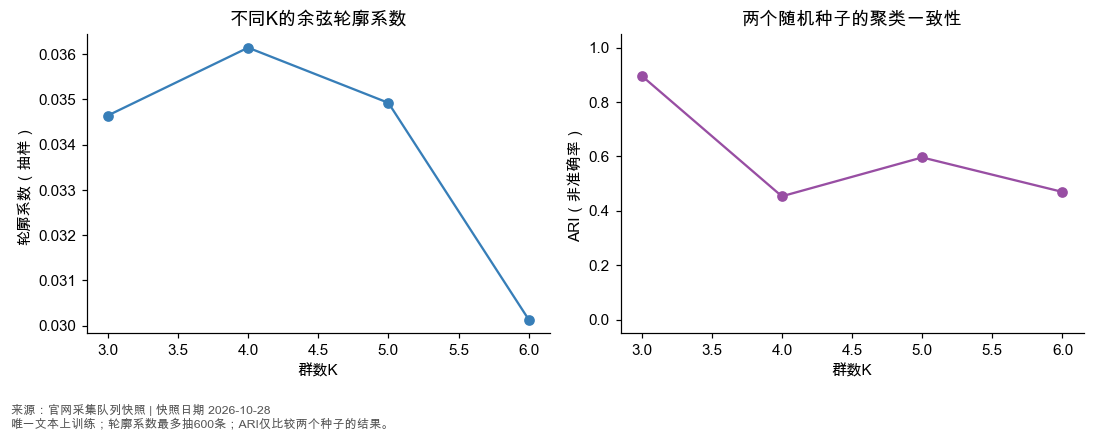

In [6]:
# 将唯一文本上的模型映射回职位，群规模此时按职位数统计，而非按唯一文本数统计。
focus['cluster'] = model.predict(focus_X)
display(comparison.round(4))
print('按预先声明规则选择 K =', best_k)
csv_export(comparison, '04_k_comparison')
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(comparison.k, comparison.silhouette_cosine, 'o-', color='#377eb8')
axes[0].set(title='不同K的余弦轮廓系数', xlabel='群数K', ylabel='轮廓系数（抽样）')
axes[1].plot(comparison.k, comparison.seed_ARI, 'o-', color='#984ea3')
axes[1].set(title='两个随机种子的聚类一致性', xlabel='群数K', ylabel='ARI（非准确率）', ylim=(-0.05, 1.05))
save_figure(fig, '04_model_comparison', '唯一文本上训练；轮廓系数最多抽600条；ARI仅比较两个种子的结果。')

## 3. 用关键词、代表岗位和公司集中度解释群

从每个中心取权重最高的词，并按到中心的欧氏距离找代表文本。
输出至少3条代表职位。`human_name`留给学生阅读后填写；`reference_name`是教师审阅当前快照代表岗位后给出的教学参考。
参考名称按关键词签名对应编号，不是模型识别出的职业真值，也未审核群内每一条职位。
模板化、来源结构和岗位级别都属于模型局限，不能凭一个词命名。

In [7]:
# 词项顺序与矩阵列、群中心向量一致；这个对应关系用于解释中心的高权重词。
terms = vectorizer.get_feature_names_out()
# 得到“每条唯一文本到各群中心”的距离矩阵，数值越小越接近该中心。
distances = model.transform(X)
cluster_rows, examples = [], []
for cluster in range(best_k):
    indices = np.flatnonzero(training.cluster.to_numpy() == cluster)
    # 先筛该群，再按到中心的距离排序取3条；代表性文本不等于对整个群的完整验证。
    nearest = indices[np.argsort(distances[indices, cluster])[:3]]
    top_terms = terms[np.argsort(model.cluster_centers_[cluster])[::-1][:12]].tolist()
    assigned = focus.loc[focus.cluster.eq(cluster)]
    company_mix = assigned['company_name'].value_counts(normalize=True)
    cluster_rows.append({'cluster': cluster, 'unique_training_texts': len(indices), 'jobs': len(assigned),
                         'top_terms': ' / '.join(top_terms), 'largest_company': company_mix.index[0],
                         'largest_company_share': float(company_mix.iloc[0]), 'human_name': '待人工命名'})
    for idx in nearest:
        row = training.iloc[idx]
        examples.append({'cluster': cluster, 'job_key': row.job_key, 'company': row.company_name,
                         'title': row.title_clean, 'text_excerpt': row.analysis_text[:700],
                         'distance_to_center': float(distances[idx, cluster]), 'review_note': ''})
cluster_summary = pd.DataFrame(cluster_rows)
representatives = pd.DataFrame(examples)
# 以下参考解释来自教师对当前快照每群3条代表文本的审阅，不是自动职业真值。
# 按关键词签名对应群编号，避免编号本身被误认为具有业务含义。
def reference_interpretation(terms):
    if '异常情况' in terms and '脚本语言' in terms:
        return '电商分析实习模板倾向'
    if '商业分析' in terms and '行业' in terms:
        return '经营与商业分析倾向'
    if '实验' in terms and '模型' in terms:
        return '实验评估与模型分析倾向'
    return '待人工解释'

In [8]:
cluster_summary['reference_name'] = cluster_summary['top_terms'].map(reference_interpretation)
display(cluster_summary)
for cluster in range(best_k):
    display(Markdown(f'### 群 {cluster}：代表职位（先阅读，再命名）'))
    display(representatives.loc[representatives.cluster.eq(cluster), ['company', 'title', 'text_excerpt']])
csv_export(cluster_summary, '04_cluster_summary')
csv_export(representatives, '04_cluster_representatives')

,cluster,unique_training_texts,jobs,top_terms,largest_company,largest_company_share,human_name,reference_name
0,0,31,45,异常情况 / 协助 / 分析师 / 脚本语言 / 迅速 / 定量分析 / 定性 / 比较 / 至少 / 解读 / 深入分析...,字节跳动,1.000000,待人工命名,电商分析实习模板倾向
1,1,547,581,数据分析 / 行业 / 策略 / 问题 / 推动 / 落地 / 商业分析 / 运营 / 目标 / 工具 / 项目 / ai,字节跳动,0.263339,待人工命名,经营与商业分析倾向
2,2,450,496,优化 / 产品 / 实验 / 评估 / 模型 / 数据分析 / 策略 / 算法 / 用户 / 机器学习 / 问题 / 方法,字节跳动,0.612903,待人工命名,实验评估与模型分析倾向


### 群 0：代表职位（先阅读，再命名）

,company,title,text_excerpt
0,字节跳动,商家产品数据科学实习生 - TikTok Shop,团队介绍：TikTok Shop 是 TikTok 旗下的内容电商。平台汇聚全球优质商家与创作者，通过短视频、直播等多场景...
1,字节跳动,国际电商数据分析实习生（全托管） - TikTok Shop,团队介绍：TikTok Shop 是 TikTok 旗下的内容电商。平台汇聚全球优质商家与创作者，通过短视频、直播等多场景...
2,字节跳动,国际电商数据科学实习生 - TikTok Shop,团队介绍：TikTok Shop 是 TikTok 旗下的内容电商。平台汇聚全球优质商家与创作者，通过短视频、直播等多场景...


### 群 1：代表职位（先阅读，再命名）

,company,title,text_excerpt
3,字节跳动,印尼服务商业务数据分析师-TikTok Shop,1、服务商业务策略分析与优化支持：独立负责基于业务与运营数据，对服务商整体业务或专项项目进行系统性分析，全面评估业务表现，...
4,阿里巴巴,淘宝闪购-商业分析专家-用户营销,1、用户健康度诊断与机会洞察：搭建并持续迭代用户健康度评估体系，围绕用户规模、活跃、留存、价值分层等核心维度开展监测与诊断...
5,阿里巴巴,高德-资深商业分析师-本地生活交易方向,1. 负责本地生活交易增长与转化效率相关的商业分析工作，围绕业务增长、交易效率提升、供需分析、核心经营指标优化等多维度分析...


### 群 2：代表职位（先阅读，再命名）

,company,title,text_excerpt
6,字节跳动,数据分析师 - 抖音用户增长,团队介绍：抖音用户增长（User Growth）负责抖音、今日头条、番茄小说等多个产品的用户增长业务，建立行业领先的增长和...
7,字节跳动,数据科学 - TikTok,团队介绍：TikTok是一个覆盖150个国家和地区的国际短视频平台，我们希望通过TikTok发现真实、有趣的瞬间，让生活更...
8,字节跳动,数据科学 - TikTok研发,团队介绍：TikTok研发团队，旨在实现TikTok业务的研发工作，搭建及维护业界领先的产品。加入我们，你能接触到包括用户...


## 4. 聚焦分析：群体技能差异与二维投影

技能词典没有参与模型训练，可作为辅助解释，但与模型输入同来自文本，不能算独立真值验证。
二维SVD只展示高维文本的投影，不用肉眼看散点替代高维评估；类别颜色不表示优劣。

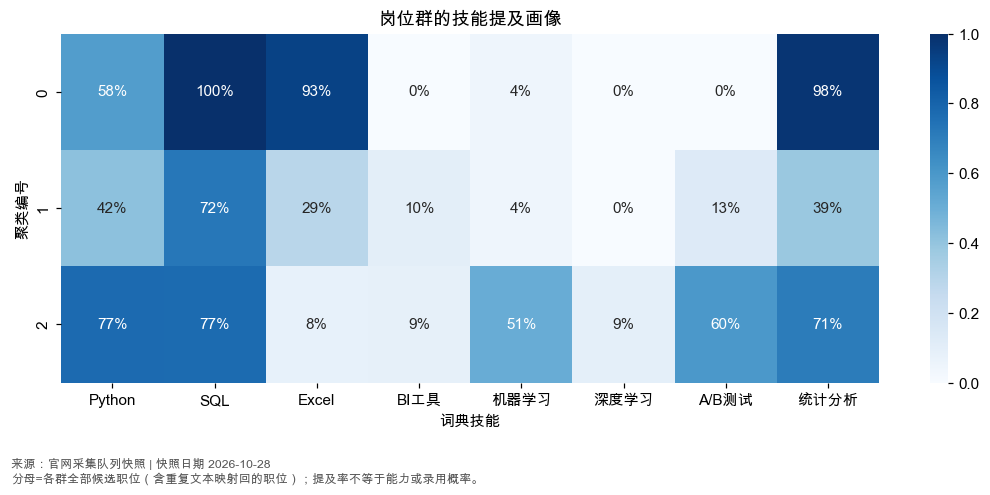

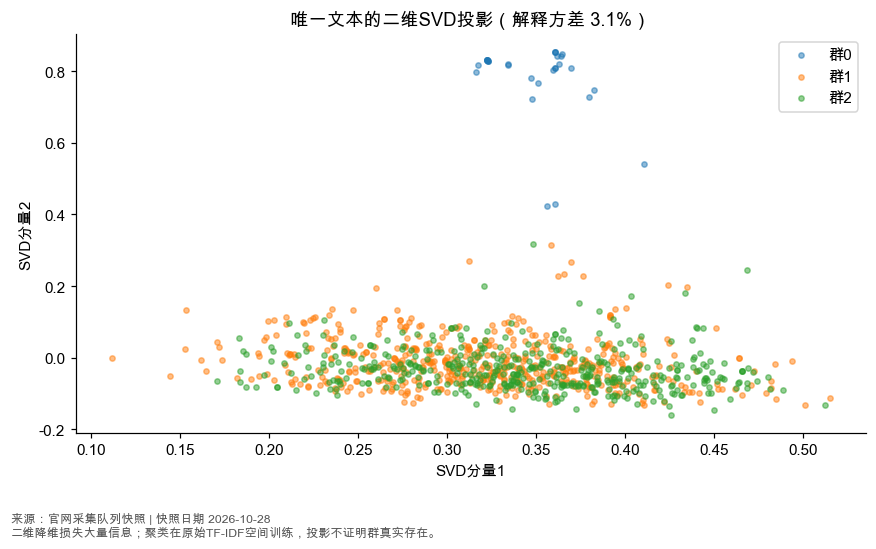

In [9]:
selected_skills = ['Python', 'SQL', 'Excel', 'BI工具', '机器学习', '深度学习', 'A/B测试', '统计分析']
# 0/1技能列的群内均值就是提及率；用词典特征辅助解释，但它与模型同来自文本。
profile = focus.groupby('cluster')[['skill_' + s for s in selected_skills]].mean()
profile.columns = selected_skills
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.heatmap(profile, annot=True, fmt='.0%', vmin=0, vmax=1, cmap='Blues', ax=ax)
ax.set(title='岗位群的技能提及画像', xlabel='词典技能', ylabel='聚类编号')
save_figure(fig, '04_cluster_skills', '分母=各群全部候选职位（含重复文本映射回的职位）；提及率不等于能力或录用概率。')
csv_export(profile.reset_index(), '04_cluster_skills')

# SVD把稀疏高维矩阵投影到二维；这里只为画图，不重新定义聚类标签。
projection = TruncatedSVD(n_components=2, random_state=SEED)
# xy的每一行仍对应training的同一行；降维丢失信息，需要同时展示解释方差。
xy = projection.fit_transform(X)
assert np.isfinite(xy).all(), '二维投影包含非有限值'
fig, ax = plt.subplots(figsize=(8, 5))
for cluster in range(best_k):
    mask = training.cluster.to_numpy() == cluster
    ax.scatter(xy[mask, 0], xy[mask, 1], s=12, alpha=0.5, label=f'群{cluster}')
ax.set(title=f'唯一文本的二维SVD投影（解释方差 {projection.explained_variance_ratio_.sum():.1%}）',
       xlabel='SVD分量1', ylabel='SVD分量2')
ax.legend()
save_figure(fig, '04_cluster_projection', '二维降维损失大量信息；聚类在原始TF-IDF空间训练，投影不证明群真实存在。')

focus['cities_list'] = focus['cities'].map(json.loads)
cluster_cities = focus[['job_key', 'cluster', 'cities_list']].explode('cities_list').dropna(subset=['cities_list'])
cluster_city_counts = cluster_cities.groupby(['cluster', 'cities_list'], as_index=False).agg(jobs=('job_key', 'nunique'))
csv_export(cluster_city_counts, '04_cluster_city_counts')
csv_export(pd.crosstab(focus.cluster, focus.company_name).reset_index(), '04_cluster_company_counts')
assert len(focus) == cluster_summary.jobs.sum()
assert representatives.groupby('cluster').size().eq(3).all()

## 4A. 【拓展】换一种特征，是否还得到同样的群？

用8个0/1技能特征再做一次相同K的聚类，与文本聚类比较ARI。
若结果不同，不代表某一方一定错误：词级模型读到了业务与职责，技能模型只看词典技能。
这种比较检验**结论对表征的敏感性**，不等同于随机种子稳定性，也没有分类准确率。

In [10]:
skill_features = focus[['skill_' + skill for skill in selected_skills]].astype(float)
# 限制数值库并行线程，减少课堂机器负载并让同一环境的重复运行更稳定。
with threadpool_limits(limits=1):
    skill_model = KMeans(n_clusters=best_k, n_init=10, random_state=SEED).fit(skill_features)
representation_ari = adjusted_rand_score(focus['cluster'], skill_model.labels_)
print('文本分群 vs 词典技能分群的ARI：', round(representation_ari, 3))

# 这里同一职位都保留：目的是对比职位标签，不混入两种去重策略的差异。
representation_table = pd.crosstab(focus['cluster'], skill_model.labels_)
representation_table.index.name = 'text_cluster'
representation_table.columns.name = 'skill_cluster'
display(representation_table)
display(skill_features.assign(skill_cluster=skill_model.labels_).groupby('skill_cluster').mean().round(3))
csv_export(representation_table.reset_index(), '04_representation_comparison')
assert representation_table.to_numpy().sum() == len(focus)

文本分群 vs 词典技能分群的ARI： 0.139


skill_cluster,0,1,2
text_cluster,,,
0,43,2,0
1,289,22,270
2,171,238,87


,skill_Python,skill_SQL,skill_Excel,skill_BI工具,skill_机器学习,skill_深度学习,skill_A/B测试,skill_统计分析
skill_cluster,,,,,,,,
0,0.805,0.988,0.368,0.165,0.00,0.002,0.316,0.704
1,0.935,0.855,0.042,0.038,1.00,0.172,0.595,0.817
2,0.006,0.356,0.154,0.028,0.05,0.006,0.162,0.143


## 4B. 【主线】追问：岗位群差异是否混入招聘类型差异？

先看各群社招、校招、实习的构成；再在同一招聘类型内比较技能。
不存在该类型的群显示缺失或不展示，不把“没有样本”填成“技能提及率0”。
即使分层后仍有差异，也只能说明描述性关联，不能认定某种岗位导致某项技能要求。

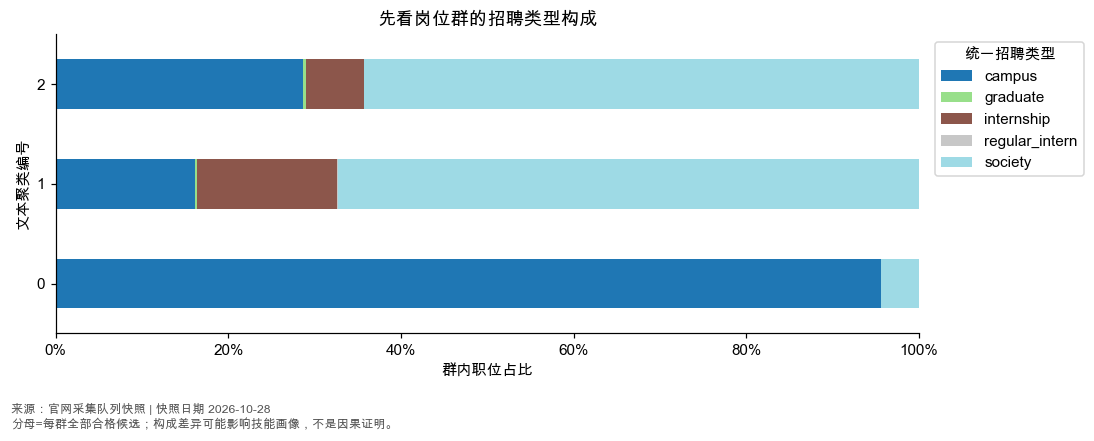

n  machine_learning_rate  ab_testing_rate  \
cluster recruitment_type                                                
0       campus             43                  0.000            0.000   
1       campus             94                  0.064            0.074   
        internship         94                  0.032            0.181   
        society           391                  0.041            0.136   
2       campus            142                  0.577            0.620   
        internship         33                  0.455            0.545   
        society           319                  0.483            0.589   

                          python_rate  
cluster recruitment_type               
0       campus                  0.558  
1       campus                  0.277  
        internship              0.511  
        society                 0.425  
2       campus                  0.824  
        internship              0.758  
        society                 0.752

In [11]:
cluster_type_counts = pd.crosstab(focus.cluster, focus.recruitment_type)
cluster_type_rates = cluster_type_counts.div(cluster_type_counts.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(10, 4))
cluster_type_rates.plot.barh(stacked=True, ax=ax, colormap='tab20')
from matplotlib.ticker import PercentFormatter
# 数据本身是0到1的小数，PercentFormatter(1)只把坐标标签显示成百分比。
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set(title='先看岗位群的招聘类型构成', xlabel='群内职位占比', ylabel='文本聚类编号', xlim=(0, 1))
# 把图例放到绘图区右边，避免遮住堆积条；具体类型仍采用数据中的统一编码映射。
ax.legend(title='统一招聘类型', bbox_to_anchor=(1.01, 1), loc='upper left')
save_figure(fig, '04_cluster_type_mix', '分母=每群全部合格候选；构成差异可能影响技能画像，不是因果证明。')
csv_export(cluster_type_counts.reset_index(), '04_cluster_type_counts')

stratified_skills = focus.groupby(['cluster', 'recruitment_type']).agg(
    n=('job_key', 'size'), machine_learning_rate=('skill_机器学习', 'mean'),
    ab_testing_rate=('skill_A/B测试', 'mean'), python_rate=('skill_Python', 'mean'))
display(stratified_skills.loc[stratified_skills.n.ge(20)].round(3))
csv_export(stratified_skills.reset_index(), '04_stratified_cluster_skills')
assert np.allclose(cluster_type_rates.sum(axis=1), 1)

## 4C. 【主线】从“分群”到“检索”：按技能兴趣找到相近岗位

聚类是先给样本分群；检索是给定查询，按相似度排序。
输入“Python SQL 实验 因果推断 数据分析”，用训练时的同一词表与IDF转换，计算余弦相似度。
相似度只代表文本接近，不代表求职者适合度、匹配成功率或录用概率。

查询词全部不在词表时会得到零向量，此时必须提示改写查询，不能把任意岗位当推荐结果。

In [12]:
from sklearn.metrics.pairwise import cosine_similarity
query_text = 'Python SQL 实验 因果推断 数据分析'
query_vector = vectorizer.transform([query_text])
assert query_vector.nnz > 0, '查询词未进入训练词表，请改写查询'
similarities = cosine_similarity(focus_X, query_vector).ravel()

# 排序前保留job_key；同一正文只展示一次，避免Top结果被复制模板占满。
retrieval = focus[['job_key', 'company_name', 'title_clean', 'city_name', 'job_url', 'text_normalized']].copy()
# 相似度数组与focus输入行序对应；先贴回对应行，再排序，避免岗位与分数错配。
retrieval['cosine_similarity'] = similarities
retrieval = retrieval.sort_values(['cosine_similarity', 'job_key'], ascending=[False, True])
# 去掉相同正文后再取前8，既不重复推荐同一模板，也不假称已做完整职位身份合并。
retrieval = retrieval.drop_duplicates('text_normalized').head(8)
display(retrieval.drop(columns=['text_normalized']).round(3))
assert retrieval.cosine_similarity.between(-1e-12, 1 + 1e-12).all()
assert retrieval.text_normalized.is_unique
csv_export(retrieval.drop(columns=['text_normalized']), '04_query_retrieval')
print('有效查询词：', [term for term in tokenize(query_text) if term in vectorizer.vocabulary_])

,job_key,company_name,title_clean,city_name,job_url,cosine_similarity
12954,12955,字节跳动,数据科学 - TikTok研发,上海,https://jobs.bytedance.com/campus/position/766448223709780613...,0.263
2128,2129,字节跳动,数据科学家（多媒体性能）-TikTok,深圳,https://jobs.bytedance.com/experienced/position/7517185802675...,0.259
13303,13304,字节跳动,数据科学（推荐方向）实习生 - TikTok Shop,北京,https://jobs.bytedance.com/campus/position/767089677584664397...,0.253
34798,34799,小红书,多媒体数据科学家-多媒体技术,北京市、上海市,https://job.xiaohongshu.com/social/position/21410,0.245
33750,33751,哔哩哔哩,数据科学家（用增策略）,上海,https://jobs.bilibili.com/social/positions/25739,0.244
19323,19324,阿里巴巴,淘天集团-数据科学专家-搜推方向,杭州,https://talent.taotian.com/off-campus/position-detail?positio...,0.224
37065,37066,滴滴,数据科学中台部-数据分析实习生,北京市,https://app.mokahr.com/apply/didiglobal/6222#/job/dfdf779b-ba...,0.215
13684,13685,字节跳动,用户增长数据分析师 - TikTok,北京,https://jobs.bytedance.com/campus/position/766865799476741970...,0.214


有效查询词： ['python', 'sql', '实验', '因果推断', '数据分析']


## 4D. 【拓展】不只看代表样本，还要看边界样本

到最近群中心距离较大的文本可能是离群岗位；第一、第二近中心距离差很小，说明归属模糊。
距离差只是诊断量，不是概率，也不能用“99%置信度”描述。
阅读这些岗位可以发现混合职责、词典不足或样本范围过宽，而不是只展示最漂亮的中心样本。

In [13]:
# 同一模型把完整候选转为到群中心的距离；与fit时输入坐标保持一致。
all_distances = model.transform(focus_X)
two_nearest = np.sort(all_distances, axis=1)[:, :2]
focus['cluster_distance'] = two_nearest[:, 0]
# 第二近距离减第一近距离；差越小，最近两个中心越难区分，但它不是校准后的置信度。
focus['cluster_distance_gap'] = two_nearest[:, 1] - two_nearest[:, 0]
boundary_jobs = focus.nsmallest(8, 'cluster_distance_gap')[
    ['job_key', 'company_name', 'title_clean', 'cluster', 'cluster_distance', 'cluster_distance_gap']]
display(boundary_jobs.round(4))
assert np.isfinite(all_distances).all()
assert focus.cluster_distance_gap.ge(-1e-12).all()
csv_export(boundary_jobs, '04_boundary_jobs')
write_json(REPORTS / 'model_extension_metrics.json', {
    'representation_ari': float(representation_ari), 'query': query_text,
    'retrieval_count': len(retrieval), 'top_retrieval_title': retrieval.iloc[0].title_clean,
    'top_retrieval_cosine': float(retrieval.iloc[0].cosine_similarity),
    'boundary_jobs': len(boundary_jobs), 'distance_is_probability': False,
})

,job_key,company_name,title_clean,cluster,cluster_distance,cluster_distance_gap
17863,17864,腾讯,灰境行者-游戏数据分析师,1,0.9593,0.0001
31063,31064,快手,数据分析专家（AI产品分析方向）-【生活服务】,1,0.8942,0.0011
11984,11985,字节跳动,数据分析（海外生活服务）实习生,1,0.9315,0.0011
25247,25248,京东,数据科学岗,2,0.9808,0.0011
37061,37062,滴滴,专车业务增长-数据分析实习生,2,0.9571,0.0012
11890,11891,字节跳动,数据分析实习生（SEA业务洞察） - TikTok Shop,1,0.9489,0.0013
37581,37582,携程,高级数据分析(MJ036451),1,0.9152,0.0014
13476,13477,字节跳动,数据科学（产品分析）实习生 - TikTok Shop,1,0.9615,0.0014


## 4E. 【课后拓展】入门监督学习：预测招聘入口编码，先战胜简单基线

聚类没有标签；分类需要标签。这里使用已有的`society/campus`编码做一个入门二分类实验，
研究问题是**文本能否帮助区分本样本的招聘入口编码**。这不是学历、岗位价值、是否能投递或个人录用预测。
campus中可能包含实习，标签来自数据入口编码，不能改称“正式工作与实习”的真值。

流程：固定子集 → 按相同处理后正文分组留出测试集 → 只在训练集fit TF-IDF → 逻辑回归 → 与多数类基线比较。
逻辑回归虽有“回归”二字，此处用于分类。测试集不能参与词表、IDF或模型参数学习。

| 指标 | 含义 |
|---|---|
| Accuracy | 全部预测中正确的比例；类别不平衡时可能误导 |
| Precision | 预测为某类的记录中，真实为该类的比例 |
| Recall | 真实为某类的记录中，被找回的比例 |
| Macro-F1 | 先对每类算F1，再等权平均，避免大类完全主导结果 |

同文分组只能防止完全相同正文跨集合，不能完全消除近似模板泄漏。结果只限同一快照留出集，
没有验证新公司或未来数据；不要把较高分数写成对招聘市场的普遍预测能力。

In [14]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

# 沿用中文为主的数据相关候选，仅保留两个已知入口编码，不重新标注其他类型。
classification_jobs = focus.loc[focus.recruitment_type.isin(['society', 'campus'])].copy().reset_index(drop=True)
# 按文本分组留出约25%的组；不是把相同模板的记录随机分散到训练和测试两边。
splitter = GroupShuffleSplit(n_splits=1, test_size=.25, random_state=SEED)
train_indices, test_indices = next(splitter.split(
    classification_jobs, groups=classification_jobs.text_normalized))
# splitter返回的是位置索引，因此使用iloc；不要把位置当作原DataFrame的标签。
train_jobs = classification_jobs.iloc[train_indices]
test_jobs = classification_jobs.iloc[test_indices]
assert set(train_jobs.text_normalized).isdisjoint(set(test_jobs.text_normalized))
assert train_jobs.recruitment_type.nunique() == test_jobs.recruitment_type.nunique() == 2
display(pd.DataFrame({'训练集': train_jobs.recruitment_type.value_counts(),
                      '测试集': test_jobs.recruitment_type.value_counts()}).fillna(0).astype(int))

# Pipeline保证向量化与模型按顺序只在训练集学习；不复用已在全候选fit过的聚类词表。
# Pipeline将只在训练集fit的向量化与分类器绑在一起，预测时复用相同词表和IDF。
classification_model = Pipeline([
    ('tfidf', TfidfVectorizer(tokenizer=tokenize, token_pattern=None, min_df=3, max_df=.9,
                             max_features=3000, sublinear_tf=True)),
    ('classifier', LogisticRegression(max_iter=500, class_weight='balanced', random_state=SEED)),
])
# 限制数值库并行线程，减少课堂机器负载并让同一环境的重复运行更稳定。
with threadpool_limits(limits=1):
    classification_model.fit(train_jobs.text_normalized, train_jobs.recruitment_type)
# 测试集只调用predict，不参与fit；保留真实标签，之后计算独立留出指标。
predictions = classification_model.predict(test_jobs.text_normalized)

,训练集,测试集
recruitment_type,,
society,533,179
campus,212,67


,model,accuracy,macro_f1,test_n
0,多数类基线,0.728,0.421,246
1,TF-IDF+逻辑回归,0.919,0.897,246


,precision,recall,f1-score,support
campus,0.851,0.851,0.851,67.000
society,0.944,0.944,0.944,179.000
accuracy,0.919,0.919,0.919,0.919
macro avg,0.897,0.897,0.897,246.000
weighted avg,0.919,0.919,0.919,246.000


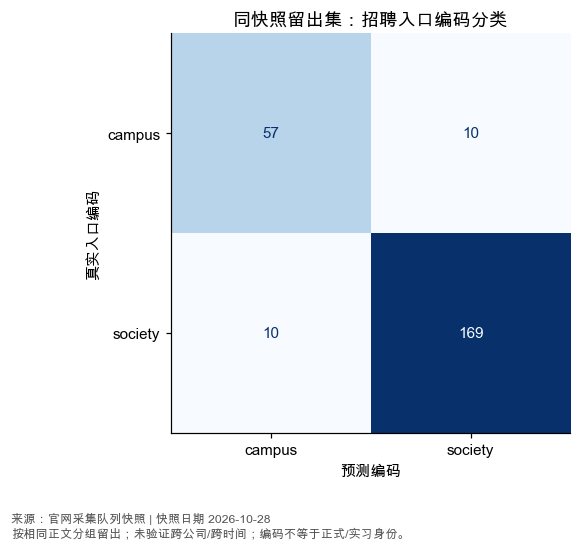

In [15]:
# 多数类基线完全不看文本；如果新模型没有超过它，就不应只展示Accuracy宣传效果。
# 这个基线始终猜训练集中最多的类别，检验复杂模型是否提供了超出类别比例的信息。
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(np.zeros((len(train_jobs), 1)), train_jobs.recruitment_type)
dummy_predictions = dummy.predict(np.zeros((len(test_jobs), 1)))
classification_scores = pd.DataFrame([
    {'model': label, 'accuracy': accuracy_score(test_jobs.recruitment_type, predicted),
     'macro_f1': f1_score(test_jobs.recruitment_type, predicted, average='macro'), 'test_n': len(test_jobs)}
    for label, predicted in [('多数类基线', dummy_predictions), ('TF-IDF+逻辑回归', predictions)]
])
display(classification_scores.round(3))
class_report = pd.DataFrame(classification_report(
    test_jobs.recruitment_type, predictions, output_dict=True, zero_division=0)).T
display(class_report.round(3))
csv_export(classification_scores, '04_classifier_scores')
csv_export(class_report.reset_index(names='label'), '04_classifier_report')

fig, ax = plt.subplots(figsize=(6.5, 5))
ConfusionMatrixDisplay.from_predictions(test_jobs.recruitment_type, predictions,
                                       labels=['campus', 'society'], cmap='Blues', ax=ax, colorbar=False)
ax.set(title='同快照留出集：招聘入口编码分类', xlabel='预测编码', ylabel='真实入口编码')
save_figure(fig, '04_classifier_confusion', '按相同正文分组留出；未验证跨公司/跨时间；编码不等于正式/实习身份。')

# 保存测试行号、实际值与预测值，供人工检查误分类，不只保留一个汇总分数。
prediction_audit = test_jobs[['job_key', 'title_clean', 'company_name', 'recruitment_type']].copy()
prediction_audit['predicted_type'] = predictions
# 逐行记录对错，方便检查误分类文本；汇总分数无法替代错误案例分析。
prediction_audit['correct'] = predictions == test_jobs.recruitment_type.to_numpy()
csv_export(prediction_audit, '04_classifier_test_predictions')

In [16]:
write_json(REPORTS / 'classifier_metrics.json', {
    'train_n': len(train_jobs), 'test_n': len(test_jobs), 'text_groups_overlap': 0,
    'target': '原始招聘入口编码campus/society', 'evaluation_scope': '同快照分组留出，非跨公司/未来验证',
    'scores': classification_scores.to_dict(orient='records'),
})

## 5. 形成报告与可写入简历的项目成果

报告中的数字自动来自前三课底稿和本课结果。手工命名与技能准确率未完成，不伪造。
把“发现一个可探索的群”与“证实一个真实职业类别”区分开来。
下一步行动：审核每群3条代表岗位和技能核验表，标记模板/语言影响，再决定调整分词或候选范围。

In [17]:
structure = json.loads((REPORTS / 'structure_metrics.json').read_text())
text_metrics = json.loads((REPORTS / 'text_metrics.json').read_text())
best = comparison.loc[comparison.k.eq(best_k)].iloc[0]
# 把样本筛选、表征维度、K和评估指标一起记录，不能只汇报一个看起来较好的分数。
cluster_metrics = {'initial_candidates': len(candidate), 'excluded_language': len(candidate)-len(focus),
                   'candidate_jobs': len(focus), 'unique_texts': len(training), 'selected_k': best_k,
                   'silhouette_cosine': float(best.silhouette_cosine), 'seed_ARI': float(best.seed_ARI),
                   'svd_2d_variance': float(projection.explained_variance_ratio_.sum()),
                   'feature_count': X.shape[1], 'random_seed': SEED}
write_json(REPORTS / 'cluster_metrics.json', cluster_metrics)
focus.drop(columns=['cities_list']).to_parquet(DATA / 'processed' / 'jobs_clustered.parquet', index=False)

summary_lines = '\n'.join(f"- 群{int(r.cluster)}（参考：{r.reference_name}）：{int(r.jobs)}条职位；最大来源{r.largest_company}占{r.largest_company_share:.1%}。"
                          for r in cluster_summary.itertuples())
business_ids = cluster_summary.loc[cluster_summary.reference_name.eq('经营与商业分析倾向'), 'cluster']
model_ids = cluster_summary.loc[cluster_summary.reference_name.eq('实验评估与模型分析倾向'), 'cluster']
interpretation = '群名需要结合代表职位与岗位构成继续审核。'
if len(business_ids) == 1 and len(model_ids) == 1:
    b, m = int(business_ids.iloc[0]), int(model_ids.iloc[0])
    interpretation = (
        f'参考解释中，群{m}的机器学习提及率为{profile.loc[m, "机器学习"]:.1%}，'
        f'群{b}为{profile.loc[b, "机器学习"]:.1%}；'
        f'A/B测试提及率分别为{profile.loc[m, "A/B测试"]:.1%}和{profile.loc[b, "A/B测试"]:.1%}。'
        '这提示数据相关岗位存在技能侧重点差异，可用于进一步筛选岗位与安排学习重点；'
        '分群边界较弱，且公司、级别、招聘类型构成不同，不能当作确定职业分类或因果效应。')

In [18]:
report = f"""# 招聘职位样本分析｜课程项目报告

## 摘要与数据范围
固定快照包含 {structure['jobs']:,} 条待同步职位、{structure['companies']} 家公司。
原库只读，通过SQLite backup API建立一致快照；原文、校验摘要和清洗日志均归档。
样本不是整个招聘市场，也不一定全部仍在线；职位条目不等于招聘人数。

## 数据质量与结构发现
- {structure['top_company']}有{structure['top_company_jobs']:,}条，占样本{structure['top_company_share']:.1%}，来源结构不均衡。
- {structure['top_city']}覆盖{structure['top_city_jobs']:,}条职位，占全部职位{structure['top_city_coverage']:.1%}；多城市覆盖率不互斥。
- 字段覆盖率存在来源差异，学历缺失不能解释为无学历要求；本项目不报告薪资排行或市场增速。
- 日期可解析率、地理层级及缺失情况见01/02课质量底稿。

## 文本分析
标题规则筛出{text_metrics['focus_candidates']}条数据相关候选岗位。
候选中Python提及率{text_metrics['focus_python_rate']:.1%}、SQL相关词提及率{text_metrics['focus_sql_rate']:.1%}。
这是职责或要求的词典命中率；不是硬性要求率或个人能力评价。
已导出{text_metrics['manual_audit_rows']}条技能命中核验样本，尚未形成带人工真值的精确率/召回率。

## 岗位聚类探索
文本长度至少40的初始候选{len(candidate)}条；排除{len(candidate)-len(focus)}条英文为主的文本后，中文为主候选{len(focus)}条。
移除明确的团队介绍、套话并分词，按处理后文本去重得到{len(training)}条训练；词级TF-IDF，固定种子42。
字符n-gram失败基线主要反映编号/模板，保留为教学反例，不用于职业方向结论。
比较K=3/4/5/6，优先筛选最小群≥20且两个种子ARI≥0.6，再选轮廓系数最高的K={best_k}。
抽样余弦轮廓系数{best.silhouette_cosine:.3f}，两个随机种子的ARI={best.seed_ARI:.3f}。
这些指标用于模型内部比较，不是分类准确率；分群仍需人工解释。
{summary_lines}

### 聚焦发现与解释边界
{interpretation}
电商分析实习模板倾向群的代表岗位正文高度相似，不能视为独立验证出的通用职业类别。
参考名称来自每群3条代表文本的人工阅读，不是对群内全部岗位的完整标注。
虽然随机种子一致性较高，轮廓系数仍较低；稳定的结果不一定有清晰职业边界。

## 可执行后续行动
1. 为每群阅读3条代表文本，填写群名称、命名理由、模板或语言影响，再决定是否保留分群。
2. 完成技能核验表的人工标注，另外抽取未命中样本，审核误报和漏报后迭代词典。
3. 对需要比较的岗位先限定招聘类型、语言与级别，并在图表中显示样本量，避免构成混杂。

## 局限与复现
京东社招采集汇总显示中断；各来源批次和采集规则不同；历史职位保留；队列不是永久全量仓库。
城市是规则清洗后的候选，省级和待核验地点不进入城市榜；词典、经验/学历正则并非完美标注。
聚类可能反映公司、语言或模板；二维投影不代表高维可分性；未作因果推断。
依次运行四本Notebook；环境版本见requirements-lock.txt；原始快照SHA见data/raw/manifest.json。
"""

In [19]:
(REPORTS / '项目分析报告.md').write_text(report, encoding='utf-8')
display(Markdown(report))

# 招聘职位样本分析｜课程项目报告

## 摘要与数据范围
固定快照包含 40,661 条待同步职位、16 家公司。
原库只读，通过SQLite backup API建立一致快照；原文、校验摘要和清洗日志均归档。
样本不是整个招聘市场，也不一定全部仍在线；职位条目不等于招聘人数。

## 数据质量与结构发现
- 字节跳动有17,053条，占样本41.9%，来源结构不均衡。
- 北京覆盖19,363条职位，占全部职位47.6%；多城市覆盖率不互斥。
- 字段覆盖率存在来源差异，学历缺失不能解释为无学历要求；本项目不报告薪资排行或市场增速。
- 日期可解析率、地理层级及缺失情况见01/02课质量底稿。

## 文本分析
标题规则筛出1138条数据相关候选岗位。
候选中Python提及率58.4%、SQL相关词提及率75.6%。
这是职责或要求的词典命中率；不是硬性要求率或个人能力评价。
已导出54条技能命中核验样本，尚未形成带人工真值的精确率/召回率。

## 岗位聚类探索
文本长度至少40的初始候选1138条；排除16条英文为主的文本后，中文为主候选1122条。
移除明确的团队介绍、套话并分词，按处理后文本去重得到1028条训练；词级TF-IDF，固定种子42。
字符n-gram失败基线主要反映编号/模板，保留为教学反例，不用于职业方向结论。
比较K=3/4/5/6，优先筛选最小群≥20且两个种子ARI≥0.6，再选轮廓系数最高的K=3。
抽样余弦轮廓系数0.035，两个随机种子的ARI=0.897。
这些指标用于模型内部比较，不是分类准确率；分群仍需人工解释。
- 群0（参考：电商分析实习模板倾向）：45条职位；最大来源字节跳动占100.0%。
- 群1（参考：经营与商业分析倾向）：581条职位；最大来源字节跳动占26.3%。
- 群2（参考：实验评估与模型分析倾向）：496条职位；最大来源字节跳动占61.3%。

### 聚焦发现与解释边界
参考解释中，群2的机器学习提及率为51.0%，群1为4.3%；A/B测试提及率分别为59.7%和13.3%。这提示数据相关岗位存在技能侧重点差异，可用于进一步筛选岗位与安排学习重点；分群边界较弱，且公司、级别、招聘类型构成不同，不能当作确定职业分类或因果效应。
电商分析实习模板倾向群的代表岗位正文高度相似，不能视为独立验证出的通用职业类别。
参考名称来自每群3条代表文本的人工阅读，不是对群内全部岗位的完整标注。
虽然随机种子一致性较高，轮廓系数仍较低；稳定的结果不一定有清晰职业边界。

## 可执行后续行动
1. 为每群阅读3条代表文本，填写群名称、命名理由、模板或语言影响，再决定是否保留分群。
2. 完成技能核验表的人工标注，另外抽取未命中样本，审核误报和漏报后迭代词典。
3. 对需要比较的岗位先限定招聘类型、语言与级别，并在图表中显示样本量，避免构成混杂。

## 局限与复现
京东社招采集汇总显示中断；各来源批次和采集规则不同；历史职位保留；队列不是永久全量仓库。
城市是规则清洗后的候选，省级和待核验地点不进入城市榜；词典、经验/学历正则并非完美标注。
聚类可能反映公司、语言或模板；二维投影不代表高维可分性；未作因果推断。
依次运行四本Notebook；环境版本见requirements-lock.txt；原始快照SHA见data/raw/manifest.json。


## 6. 【项目交付】把扩展实验写进一份有证据的报告

结论应写成：现象→比较→数值证据→解释边界→下一步核验。
下面自动汇总累计贡献、多城市分摊、技能关联、表征敏感性与检索实验，
给出更完整的项目报告。学生应替换为自己的独立问题和经核验发现。

In [20]:
structure_more = json.loads((REPORTS / 'structure_extension_metrics.json').read_text())
text_more = json.loads((REPORTS / 'text_extension_metrics.json').read_text())
model_more = json.loads((REPORTS / 'model_extension_metrics.json').read_text())
classifier_more = json.loads((REPORTS / 'classifier_metrics.json').read_text())
pair = text_more['top_supported_pair']

# 从真实底稿取数，不把先前版本的结论复制成不可更新的常量。
extended_findings = [
    f"样本累计贡献：前{structure_more['companies_to_80pct']}家公司达到80%职位覆盖，来源HHI为{structure_more['source_hhi']:.3f}；这是样本集中度。",
    f"城市分摊守恒：折算贡献{structure_more['fractional_city_total']:,.0f}条，加无城市候选{structure_more['no_city_jobs']:,}条，回到全量职位数。",
    f"技能组合：{pair['a']}与{pair['b']}共同提及{int(pair['n_ab'])}条，Lift={pair['lift']:.2f}；有最低支持数，但不是因果或显著性结论。",
    f"表征敏感性：同一候选下文本与技能特征分群ARI={model_more['representation_ari']:.3f}；研究对象和特征定义会影响岗位群。",
    f"文本检索：查询“{model_more['query']}”返回{model_more['retrieval_count']}条去重结果，最高相似度{model_more['top_retrieval_cosine']:.3f}；不是录用概率。",
    f"监督学习拓展：同快照分组测试集{classifier_more['test_n']}条，逻辑回归Macro-F1={classifier_more['scores'][1]['macro_f1']:.3f}，多数类基线={classifier_more['scores'][0]['macro_f1']:.3f}；仅预测入口编码，未验证新公司或未来数据。",
]
extra_report = report + '\n\n## 扩展分析与比较实验\n' + '\n'.join('- ' + line for line in extended_findings)
extra_report += '\n\n## 独立练习后的STAR补充\n'
extra_report += ('完成SQL与Pandas一致性核验、一对多关联检查、多城市双口径分析；'
                 '将职责和要求转为技能、语境与证据列，比较文本与技能表征下的聚类，建立可解释的相似岗位检索原型。'
                 '仅完成独立练习和人工核验后，才将这些步骤写成自己的项目贡献。')
(REPORTS / '项目分析报告_增强版.md').write_text(extra_report, encoding='utf-8')
display(Markdown('\n\n'.join('**发现**：' + line for line in extended_findings)))

**发现**：样本累计贡献：前7家公司达到80%职位覆盖，来源HHI为0.211；这是样本集中度。

**发现**：城市分摊守恒：折算贡献39,689条，加无城市候选972条，回到全量职位数。

**发现**：技能组合：Spark与Hadoop/Hive共同提及71条，Lift=5.78；有最低支持数，但不是因果或显著性结论。

**发现**：表征敏感性：同一候选下文本与技能特征分群ARI=0.139；研究对象和特征定义会影响岗位群。

**发现**：文本检索：查询“Python SQL 实验 因果推断 数据分析”返回8条去重结果，最高相似度0.263；不是录用概率。

**发现**：监督学习拓展：同快照分组测试集246条，逻辑回归Macro-F1=0.897，多数类基线=0.421；仅预测入口编码，未验证新公司或未来数据。

### 综合练习：从一个真实问题独立完成闭环

三选一：①数据分析与数据科学的技能差异；②限定社招后两家公司的岗位侧重点；③修改查询词构建技能学习方向的职位检索。

交付要求：
1. 写清样本筛选条件、行单位、分母与至少一项数据质量限制。
2. 自己新增1个特征或1条技能规则，并提供正反例与10条人工检查。
3. 提交2张自己的图、1张底稿、3条带数字结论；解释至少一种替代口径。
4. 模型方向须比较至少两个方案，阅读中心与边界岗位；检索方向须说明零向量和重复文本的处理。
5. 用STAR写150字项目概括，明确自己做了哪些分析，不把教师代码与原始采集算成独立开发。

**教师参考追问**：你改了分母吗？你排除了哪些样本？如果换一种特征，结论还成立吗？
如果不能成立，应报告适用边界，而不是删掉不支持结论的结果。

## STAR 项目表述与课堂汇报

**S**：多公司招聘数据嵌套在 JSON 中，岗位职责与要求难以直接比较。  
**T**：构建分析表，描述样本结构，提取技能并探索数据相关岗位的细分群体。  
**A**：使用 SQLite/Pandas 清洗与展开，Matplotlib/Seaborn 可视化，技能词典/TF-IDF 文本特征，KMeans聚类。  
**R**：交付可复现分析、图表底稿和报告；具体样本量、候选数、群数以运行结果为准。

简历示例：
> 基于16家公司官网采集样本完成招聘岗位分析，使用Python/SQL展开JSON并统一多城市统计口径；
> 结合技能词典与TF-IDF提取文本特征，使用KMeans探索数据相关岗位群，交付可复现Notebook与分析报告。

请在完成独立练习后补充一条经核验的具体发现。不要声称自己完成了原始采集系统，也不要把聚类写成录用预测。

## 最后15分钟：项目答辩

1. 用30秒说明样本和研究问题，60秒讲一张图，60秒讲一个技能/岗位群，30秒讲局限。
2. 为什么选择这个K？如果ARI较低怎么办？（检查稳定性，缩小范围，修改表征，而非只挑漂亮图。）
3. 可选拓展：改变停用词、min_df或标题筛选范围，对比关键词、代表职位与结果稳定性，不只比一个指标。

**验收**：候选数与群计数对齐；每群有3条代表文本；指标口径公开；报告中的数字与底稿一致。